# Wave-following diagnostics, single ensemble member
Generates a time series of a user specified box average following the wave, from data using the QTRACK tool (Lawton, et al. 2022)

In [59]:
from __future__ import print_function
import pkg_resources
import os
#from os import listdir
#from os.path import isfile, join
import glob
import metpy
import subprocess
import wrf
import numpy as np
from netCDF4 import Dataset

import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
import matplotlib.cbook as cbook
import cartopy.crs as crs
import cartopy.feature as cfeature
from metpy.units import units

from cartopy.feature import NaturalEarthFeature

from wrf import (to_np, interplevel, geo_bounds, getvar, smooth2d, get_cartopy, cartopy_xlim,
                 cartopy_ylim, latlon_coords, destagger)
from matplotlib.colors import Normalize
import matplotlib.patches as mpatches


from metpy.plots import ctables

import metpy.calc as mpcalc
import xarray as xr
import pandas as pd

In [60]:
## The following are lists to select each ensemble set and respective initialization time
variation = ['fluxon', 'rst_on24', 'rst_on36', 'rst_on48', '', 'fluxoff', '', '', '']
vartitles  = ['control', 'noflux24hr', 'noflux36hr', 'noflux48hr', '', 'fluxoff', '', '', '']
titles = [
    'Control',
    '24 hours without fluxes',
    '36 hours without fluxes',
    '48 hours without fluxes',
    '',
    'Fluxes off',
    '',
    '',
    ''
]
init_times = ['0300','0303','0306',
             '0309','0312','0315',
             '0318','0321','0400']

In [70]:
#########################################
### MAKE SELECTIONS HERE
wave = 'second'             # 'second' == Paulette or 'main' == Rene
var_index = 3

set_name = variation[var_index]     # try: variation[1]
vartitle = vartitles[var_index]
title = titles[var_index]  # What will be displayed on main plot
ens = init_times[4]


## 
if wave == 'main':
    name = 'Rene'
else:
    name = 'Paulette'

In [71]:
plotsdir = '/glade/u/home/athornton/qtrack/'

In [72]:
save_name = set_name +"_"+ ens
print(save_name)
title_name = vartitle+"_"+ens
print(title_name)

rst_on48_0312
noflux48hr_0312


## First get the track of the wave

In [73]:
df = xr.open_dataset('/glade/u/home/athornton/qtrack/'+wave+'_wave/'+wave+'_wave_track_'+save_name+'.nc')

## Now get the corresponding WRF run
We will select only the data from the wrf run that corresponds to this wave track, in a 1x1 degree box following the wave. 

In [74]:
# Set directory where wrfout files reside, and list the files for processing.  Set up for a directory with only wrfout files.
os.chdir("/glade/campaign/univ/uncs0067/flux_experiments/cent_atl_case/init"+ens+"z/"+set_name+"/")
#plotsdir = "/glade/u/home/athornton/wrf_visualization/plots/restart/init"+ens+"z/"+set_name+"/"
plotsdir = '/glade/u/home/athornton/qtrack/'

In [75]:
datafiles = sorted(glob.glob("./wrfout*"))
numfiles=len(datafiles)
print(numfiles)
print(datafiles[0])

49
./wrfout_d01_2020-09-03_12:00:00


In [76]:
# From Anantha...
# Simple linear interpolation between each latitude point
def get_lats():
    new_lats = []
    wave_track_lats = df.lat[-len(times_list):]
    for i in range(0,len(wave_track_lats)):
        if wave_track_lats[i] == wave_track_lats[-1]:
            new_lats.append(wave_track_lats[i].values)
        else:
            next_value = 0.5*(wave_track_lats[i] + wave_track_lats[i+1])
            new_lats.append(wave_track_lats[i].values)
            new_lats.append(next_value.values)
    return new_lats

In [77]:
# From Anantha...
# Simple linear interpolation between each longitude point
def get_lons():
    new_lons = []
    wave_track_lons = df.lon[-len(times_list):] 
    for i in range(0,len(wave_track_lons)):
        if wave_track_lons[i] == wave_track_lons[-1]:
            new_lons.append(wave_track_lons[i].values)
        else:
            next_value = 0.5*(wave_track_lons[i] + wave_track_lons[i+1])
            new_lons.append(wave_track_lons[i].values)
            new_lons.append(next_value.values)
    return new_lons

In [78]:
init_time ='2020-09-'+ens[:2]+' '+ens[2:]+':00'
end_time  ='2020-09-09 12:00'

In [79]:
times_list = pd.date_range(start=init_time, end=end_time, freq='6h')

In [80]:
wave_track_lats = get_lats()
wave_track_lons = get_lons()

In [81]:
wrf_out_data = xr.open_dataset(datafiles[0])  
p =wrf_out_data['P']
pb = wrf_out_data['PB'].metpy.quantify()

In [82]:
def mass_weighted_vert_integral(height, data):
    # data is expected to be on pressure levels
    levels = height[0,:,0,0]#.metpy.convert_units('Pa')
    print(levels)
    deltaP = (levels - levels.shift(bottom_top=-1))#.metpy.convert_units('Pa')
    print(deltaP)
    vert_int_data = ((data.shift(bottom_top=-1)+data)*.5*deltaP).sum(dim='bottom_top') / metpy.constants.earth_gravity    
    return  vert_int_data

In [83]:
# Set up loop to run same plots for multiple different times (assume here that we have 1 time per wrfout file)
winds_list = []
moist_list = []
vo850_list = []
vo700_list = []
vo600_list = []

WRF_OUT_DATA = [] 
date = []

for i in range(0,len(datafiles)):
    # for j in range(0,1):
    ncfile = Dataset(datafiles[i])
    Time=wrf.extract_times(ncfile, timeidx=0, method='cat', squeeze=True, cache=None, meta=False, do_xtime=False)
    timestr=(str(Time))
    # Set up one time string for plot titles, another for file names
    titletime=(timestr[0:10]+' '+timestr[11:16])
    filetime=(timestr[0:10]+'_'+timestr[11:16])
    print('WRF valid time: ',filetime)

    wrf_out_data = xr.open_dataset(datafiles[i])  
    WRF_OUT_DATA.append(wrf_out_data)
    time = wrf_out_data['XTIME'][0].values
    time_changed = time.astype(np.datetime64)
    ts = pd.to_datetime(str(time_changed))
    d = ts.strftime('%Y-%m-%d %H:%M')
    date.append(d)
    
    # Get all the variables we need

    qwv = wrf_out_data["QVAPOR"].metpy.quantify()
    #p = wrf_out_data['P'].metpy.quantify()    
    ua = wrf_out_data["U"]#.metpy.quantify()  
    va = wrf_out_data["V"]#.metpy.quantify()  

    lats, lons = latlon_coords(wrf_out_data['P'])
    lats_np = to_np(lats)
    lons_np = to_np(lons)
    lats_np = lats_np[0,:,0]
    lons_np = lons_np[0,0,:]
    
    # Unstagger the winds to match the pressure grid
    ua = destagger(ua, stagger_dim=3)             # Unstagger U in the x-direction
    va = destagger(va, stagger_dim=2)             # Unstagger V in the x-direction

    # Grid spacing for vorticity calculation
    dx = ncfile.DX * units("m")
    dy = ncfile.DY * units("m")
    
    u_winds = xr.DataArray(ua)[0]
    v_winds = xr.DataArray(va)[0]
    qwv =  xr.DataArray(qwv)[0]
    
    u_sfc = u_winds.sel(dim_1=1)*units('m/s')     # select surface winds
    v_sfc = v_winds.sel(dim_1=1)*units('m/s')     # select surface winds
    wind_sfc = mpcalc.wind_speed(u_sfc, v_sfc)

    u_600 = u_winds.sel(dim_1=19)*units('m/s')    # select 630 hPa winds
    v_600 = v_winds.sel(dim_1=19)*units('m/s')    # select 630 hPa winds
    vo600=metpy.calc.vorticity(u_600, v_600, dx=dx, dy=dy)
    vo600=to_np(vo600)

    u_700 = u_winds.sel(dim_1=17)*units('m/s')    # select 700 hPa winds
    v_700 = v_winds.sel(dim_1=17)*units('m/s')    # select 700 hPa winds 
    vo700=metpy.calc.vorticity(u_700, v_700, dx=dx, dy=dy)
    vo700=to_np(vo700)
    
    u_850 = u_winds.sel(dim_1=12)*units('m/s')    # select 850 hPa winds
    v_850 = v_winds.sel(dim_1=12)*units('m/s')    # select 850 hPa winds
    vo850=metpy.calc.vorticity(u_850, v_850, dx=dx, dy=dy)
    vo850=to_np(vo850)
    
    try:
        lat_lon = [wave_track_lats[i],wave_track_lons[i]]     # Lat, Lon cooridante of center of square we are interested in
    except IndexError:
        lat_lon = [wave_track_lats[i-1],wave_track_lons[i-1]] # if the last datapoint does not have a track, keep the datapoint from before
    
    x_ycenter = wrf.ll_to_xy(ncfile, lat_lon[0], lat_lon[1])

    # specify how big you want the wave-following box to be
    delta = 50                                      # in grid points 

    winds = wind_sfc[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)]

    # wave tracks have nans at the beginning so return nan if it's the beginning of the track
    if not winds.any():
        max_wind = np.nan
    else:
        max_wind = np.max(winds.values)

    columnq = mass_weighted_vert_integral(pb, qwv)
    avg_qwv = columnq[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)].mean()
    avg_850 = vo850[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)].mean()
    avg_700 = vo700[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)].mean()
    avg_600 = vo600[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)].mean()

    winds_list.append(max_wind)
    moist_list.append(avg_qwv)
    vo850_list.append(avg_850)
    vo700_list.append(avg_700)
    vo600_list.append(avg_600)
    

WRF valid time:  2020-09-03_12:00


/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:60: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo600=metpy.calc.vorticity(u_600, v_600, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:65: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo700=metpy.calc.vorticity(u_700, v_700, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:70: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo850=metpy.calc.vorticity(u_850, v_850, dx=dx, dy=dy)


<xarray.DataArray 'PB' (bottom_top: 49)> Size: 196B
<Quantity([99715.    99097.5   98385.    97577.5   96675.    95677.5   94585.
 93397.5   92067.5   90547.5   88837.51  86890.    84657.5   82140.
 79385.    76440.    73305.    69980.    66512.5   62973.75  59392.25
 55772.75  52148.5   48571.75  45090.    41741.25  38582.5   35685.
 33167.5   31077.502 29272.5   27657.5   26232.5   24950.002 23762.498
 22608.25  21430.25  20228.5   18993.5   17725.25  16428.5   15112.75
 13787.5   12448.    11099.     9750.     8401.     7052.     5688.75 ], 'pascal')>
Coordinates:
    XLAT     float32 4B ...
    XLONG    float32 4B ...
    XTIME    datetime64[ns] 8B ...
Dimensions without coordinates: bottom_top
Attributes:
    FieldType:    104
    MemoryOrder:  XYZ
    description:  BASE STATE PRESSURE
    stagger:      
<xarray.DataArray 'PB' (bottom_top: 49)> Size: 196B
<Quantity([ 617.5     712.5     807.5     902.5     997.5    1092.5    1187.5
 1330.     1520.     1709.9922 1947.5078 2232.5  

/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:60: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo600=metpy.calc.vorticity(u_600, v_600, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:65: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo700=metpy.calc.vorticity(u_700, v_700, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:70: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo850=metpy.calc.vorticity(u_850, v_850, dx=dx, dy=dy)


<xarray.DataArray 'PB' (bottom_top: 49)> Size: 196B
<Quantity([99715.    99097.5   98385.    97577.5   96675.    95677.5   94585.
 93397.5   92067.5   90547.5   88837.51  86890.    84657.5   82140.
 79385.    76440.    73305.    69980.    66512.5   62973.75  59392.25
 55772.75  52148.5   48571.75  45090.    41741.25  38582.5   35685.
 33167.5   31077.502 29272.5   27657.5   26232.5   24950.002 23762.498
 22608.25  21430.25  20228.5   18993.5   17725.25  16428.5   15112.75
 13787.5   12448.    11099.     9750.     8401.     7052.     5688.75 ], 'pascal')>
Coordinates:
    XLAT     float32 4B ...
    XLONG    float32 4B ...
    XTIME    datetime64[ns] 8B ...
Dimensions without coordinates: bottom_top
Attributes:
    FieldType:    104
    MemoryOrder:  XYZ
    description:  BASE STATE PRESSURE
    stagger:      
<xarray.DataArray 'PB' (bottom_top: 49)> Size: 196B
<Quantity([ 617.5     712.5     807.5     902.5     997.5    1092.5    1187.5
 1330.     1520.     1709.9922 1947.5078 2232.5  

/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:60: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo600=metpy.calc.vorticity(u_600, v_600, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:65: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo700=metpy.calc.vorticity(u_700, v_700, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:70: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo850=metpy.calc.vorticity(u_850, v_850, dx=dx, dy=dy)


... (89 outputs left out)

/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:60: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo600=metpy.calc.vorticity(u_600, v_600, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:65: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo700=metpy.calc.vorticity(u_700, v_700, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:70: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo850=metpy.calc.vorticity(u_850, v_850, dx=dx, dy=dy)


<xarray.DataArray 'PB' (bottom_top: 49)> Size: 196B
<Quantity([99715.    99097.5   98385.    97577.5   96675.    95677.5   94585.
 93397.5   92067.5   90547.5   88837.51  86890.    84657.5   82140.
 79385.    76440.    73305.    69980.    66512.5   62973.75  59392.25
 55772.75  52148.5   48571.75  45090.    41741.25  38582.5   35685.
 33167.5   31077.502 29272.5   27657.5   26232.5   24950.002 23762.498
 22608.25  21430.25  20228.5   18993.5   17725.25  16428.5   15112.75
 13787.5   12448.    11099.     9750.     8401.     7052.     5688.75 ], 'pascal')>
Coordinates:
    XLAT     float32 4B ...
    XLONG    float32 4B ...
    XTIME    datetime64[ns] 8B ...
Dimensions without coordinates: bottom_top
Attributes:
    FieldType:    104
    MemoryOrder:  XYZ
    description:  BASE STATE PRESSURE
    stagger:      
<xarray.DataArray 'PB' (bottom_top: 49)> Size: 196B
<Quantity([ 617.5     712.5     807.5     902.5     997.5    1092.5    1187.5
 1330.     1520.     1709.9922 1947.5078 2232.5  

/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:60: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo600=metpy.calc.vorticity(u_600, v_600, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:65: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo700=metpy.calc.vorticity(u_700, v_700, dx=dx, dy=dy)
/glade/derecho/scratch/athornton/tmp/ipykernel_119287/3365924055.py:70: UserWarning: Horizontal dimension numbers not found. Defaulting to (..., Y, X) order.
  vo850=metpy.calc.vorticity(u_850, v_850, dx=dx, dy=dy)


<xarray.DataArray 'PB' (bottom_top: 49)> Size: 196B
<Quantity([99715.    99097.5   98385.    97577.5   96675.    95677.5   94585.
 93397.5   92067.5   90547.5   88837.51  86890.    84657.5   82140.
 79385.    76440.    73305.    69980.    66512.5   62973.75  59392.25
 55772.75  52148.5   48571.75  45090.    41741.25  38582.5   35685.
 33167.5   31077.502 29272.5   27657.5   26232.5   24950.002 23762.498
 22608.25  21430.25  20228.5   18993.5   17725.25  16428.5   15112.75
 13787.5   12448.    11099.     9750.     8401.     7052.     5688.75 ], 'pascal')>
Coordinates:
    XLAT     float32 4B ...
    XLONG    float32 4B ...
    XTIME    datetime64[ns] 8B ...
Dimensions without coordinates: bottom_top
Attributes:
    FieldType:    104
    MemoryOrder:  XYZ
    description:  BASE STATE PRESSURE
    stagger:      
<xarray.DataArray 'PB' (bottom_top: 49)> Size: 196B
<Quantity([ 617.5     712.5     807.5     902.5     997.5    1092.5    1187.5
 1330.     1520.     1709.9922 1947.5078 2232.5  

## Now get rain data

In [84]:
# open all wrfout files for this ensemble member
data = xr.open_mfdataset(datafiles, concat_dim='Time', combine='nested', engine='netcdf4')
rain = data.RAINC
time = data.XTIME.compute()
rain_list = [np.zeros_like(rain[0])]  # Start with a zero array for the first time step

for i in range(1, len(rain)):
    rain_hour = rain[i] - rain[i-1] # subtract computed accumulated rain note from previous timestep
    rain_hour = np.maximum(rain_hour, 0)  # Set negative values to 0
    rain_list.append(rain_hour)

rain = xr.DataArray(rain_list)

In [85]:
# Apply wavetrack to this rain data and only choose points within our wave-following box
rain_box_list = []
for i in range(0,len(datafiles)):
    try:
        lat_lon = [wave_track_lats[i],wave_track_lons[i]]                 # Lat, Lon cooridante of center of square we are interested in
    except IndexError:
        lat_lon = [wave_track_lats[i-1],wave_track_lons[i-1]] # if the last datapoint does not have a track, keep the datapoint from before
    
    x_ycenter = wrf.ll_to_xy(ncfile, lat_lon[0], lat_lon[1])

    # specify how big you want the wave-following box to be
    delta = 50                                # in grid points 
    rain_inc = rain[i]
    rain_box = rain_inc[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)].mean()
    rain_box_list.append(rain_box)

In [86]:
times = pd.date_range(init_time, end_time, freq='3h')

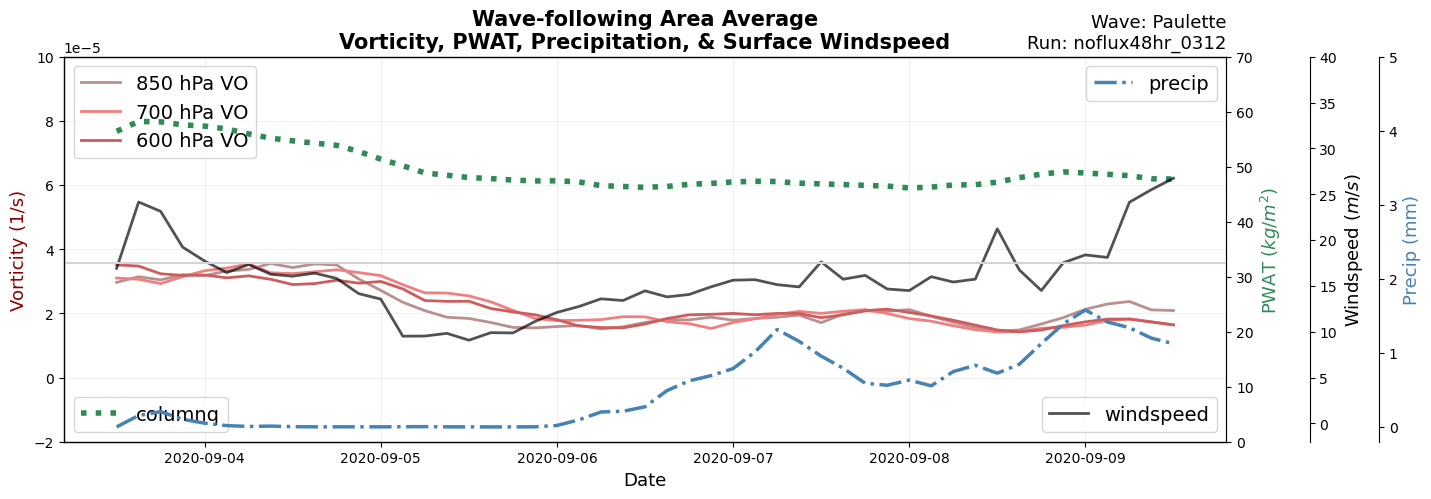

In [87]:
plt.rcParams['savefig.dpi'] = 255
fig, ax = plt.subplots(figsize=(15,5))

ax.set_title('Wave-following Area Average\nVorticity, PWAT, Precipitation, & Surface Windspeed', size=15, weight='bold')
#ax.set_title(wave, loc='right')
plt.title('Wave: '+name+'\nRun: '+title_name, loc='right', fontsize=13)
ax.set_ylabel('Vorticity (1/s)', color='darkred',size =13)
ax.set_xlabel('Date', size=13)
ax.plot(times, vo850_list, color='rosybrown', label='850 hPa VO', linewidth=2.)
ax.plot(times, vo700_list, color='lightcoral', label='700 hPa VO', linewidth=2.)
ax.plot(times, vo600_list, color='indianred', label='600 hPa VO', linewidth=2.)
ax.set_ylim(-0.00002,0.00010)
ax.legend(loc='upper left', fontsize=14)

ax2=ax.twinx()
ax2.plot(times, moist_list, color='seagreen', label='columnq', linestyle=':', linewidth=4.)
ax2.set_ylim(0.,70)
ax2.legend(loc='lower left', fontsize=14)
ax2.set_ylabel('PWAT ($kg/m^2$)', size=13, color='seagreen')

ax3=ax.twinx()
ax3.plot(times, winds_list, color='black', label='windspeed', linewidth=2., alpha=0.68)
ax3.set_ylim(-2,40)
ax3.set_ylabel('Windspeed ($m/s$)', size=13, color='black')
ax3.spines['right'].set_position(('outward', 60))
ax3.legend(loc='lower right', fontsize=14)

ax4=ax.twinx()
ax4.plot(times, rain_box_list, color='steelblue', label='precip', linestyle='-.', linewidth=2.5)
ax4.set_ylim(-0.2,5)
ax4.spines['right'].set_position(('outward', 110))
ax4.set_ylabel('Precip (mm)', size=13, color='steelblue')
ax4.legend(loc='upper right', fontsize=14)
ax.grid(color='lightgray',alpha=0.3)

ax3.axhline(y=17.5, color='lightgray')

plt.savefig(plotsdir+'wave_following_'+wave+'_'+save_name+'.png')
